In [31]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [32]:
import pandas as pd
import numpy as np

np.random.seed(202)

user_ids = np.arange(0, 500)

# Simulate features with hidden relationships to churn
account_age_days = np.random.randint(10, 365, size=500)
total_events = account_age_days * np.random.uniform(0.1, 2.5, size=500)
core_actions_ratio = np.random.uniform(0.0, 1.0, size=500)
teammates_invited = np.random.choice([0, 1, 2, 3, 5, 10], size=500, p=[0.4, 0.2, 0.15, 0.1, 0.1, 0.05])
support_tickets = np.random.poisson(lam=1.5, size=500)

# Create a complex, non-linear logic for true churn
# Churn is highly likely if: No teammates, high support tickets, and low core actions
churn_prob_hidden = (
    (teammates_invited == 0) * 0.4 +
    (support_tickets > 3) * 0.3 + 
    (core_actions_ratio < 0.2) * 0.2 +
    (account_age_days < 30) * 0.1
)

is_churned = np.random.binomial(1, np.clip(churn_prob_hidden, 0, 1))

df = pd.DataFrame({
    'user_id': user_ids,
    'account_age_days': account_age_days,
    'total_events': total_events,
    'core_actions_ratio': core_actions_ratio,
    'teammates_invited': teammates_invited,
    'support_tickets': support_tickets,
    'Is_Churned': is_churned
})

In [33]:
df

,user_id,account_age_days,total_events,core_actions_ratio,teammates_invited,support_tickets,Is_Churned
0,0,161,75.788863,0.606162,10,1,0
1,1,70,113.766203,0.354859,3,0,0
2,2,306,730.328321,0.598691,2,1,0
3,3,195,476.004871,0.434430,1,1,0
4,4,273,125.804630,0.447633,3,1,0
...,...,...,...,...,...,...,...
495,495,334,795.765151,0.311649,2,1,0
496,496,340,711.996163,0.936402,0,1,1
497,497,133,262.706854,0.744424,0,3,0
498,498,70,16.251535,0.637605,0,2,0


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   user_id             500 non-null    int64  
 1   account_age_days    500 non-null    int64  
 2   total_events        500 non-null    float64
 3   core_actions_ratio  500 non-null    float64
 4   teammates_invited   500 non-null    int64  
 5   support_tickets     500 non-null    int64  
 6   Is_Churned          500 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 27.5 KB


In [35]:
df['Is_Churned'].value_counts()

Is_Churned
0    393
1    107
Name: count, dtype: int64

In [36]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


In [37]:
X = df[['account_age_days','total_events','core_actions_ratio','teammates_invited','support_tickets']]
y = df['Is_Churned']

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
model = RandomForestClassifier(n_estimators = 15, random_state=42)

model.fit(X_train,y_train)
y_pred= model.predict(X_test)
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           0       0.92      0.85      0.88        86
           1       0.38      0.57      0.46        14

    accuracy                           0.81       100
   macro avg       0.65      0.71      0.67       100
weighted avg       0.85      0.81      0.82       100



In [39]:
model = RandomForestClassifier(n_estimators = 15, random_state=42,class_weight = 'balanced')

model.fit(X_train,y_train)
y_pred= model.predict(X_test)
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           0       0.95      0.85      0.90        88
           1       0.38      0.67      0.48        12

    accuracy                           0.83       100
   macro avg       0.67      0.76      0.69       100
weighted avg       0.88      0.83      0.85       100



### NOTE -> Advanced Modeling Technique will be applied in phase 2 (Project)

In [40]:
#Import the SHAP package
import shap

# Initialize SHAP TreeExplainer for our XGBoost model
explainer = shap.TreeExplainer(model)

# Calculate SHAP values for our test set
print("Calculating SHAP values...")
shap_values = explainer(X_test)

print(f"SHAP values calculated for {shap_values.shape[0]} predictions")
print(f"Each prediction explained by {shap_values.shape[1]} features")

explainer.expected_value

Calculating SHAP values...
SHAP values calculated for 100 predictions
Each prediction explained by 5 features


array([0.49905443, 0.50094557])

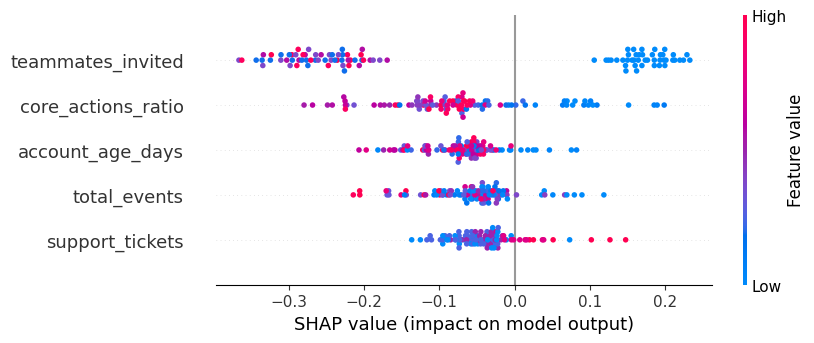

In [41]:
# Global Interpretability (beeswarm plot for positive class)
shap.plots.beeswarm(shap_values[:, :, 1])

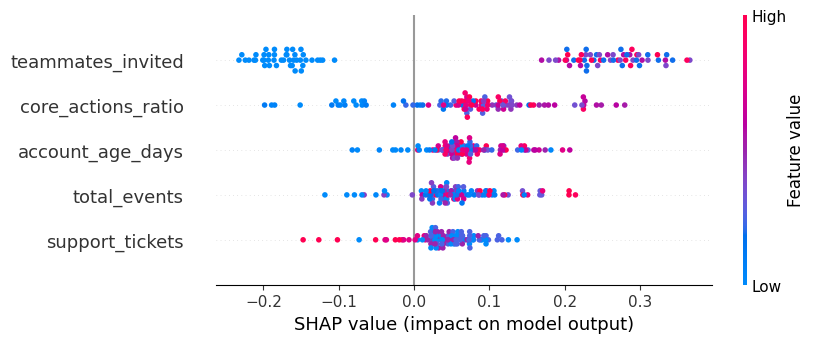

In [42]:
# Global Interpretability (beeswarm plot for negative class)
shap.plots.beeswarm(shap_values[:, :, 0])

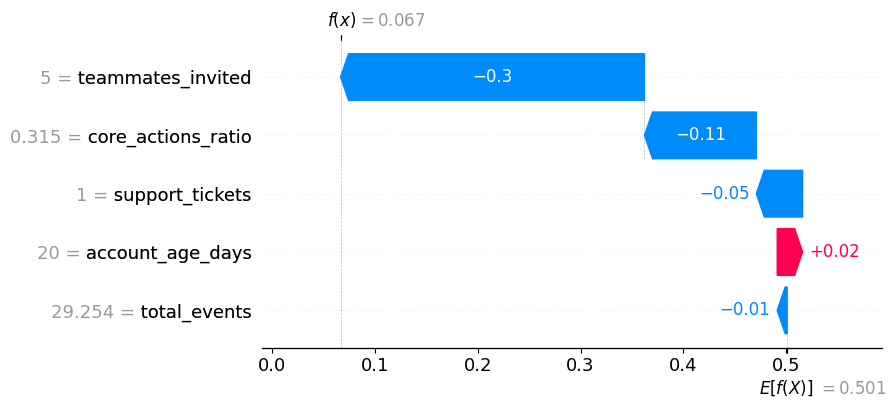

In [43]:
# Waterfall plot for first row of test set (Local Interpretability)
shap.plots.waterfall(shap_values[0, :, 1])

### Plotting for the most churn probability cutomer of Save at all Cost (Seg1)

In [44]:
entire_shap = explainer(X)

In [45]:
df[df['user_id']==323]

,user_id,account_age_days,total_events,core_actions_ratio,teammates_invited,support_tickets,Is_Churned
323,323,95,42.235545,0.39068,0,2,0


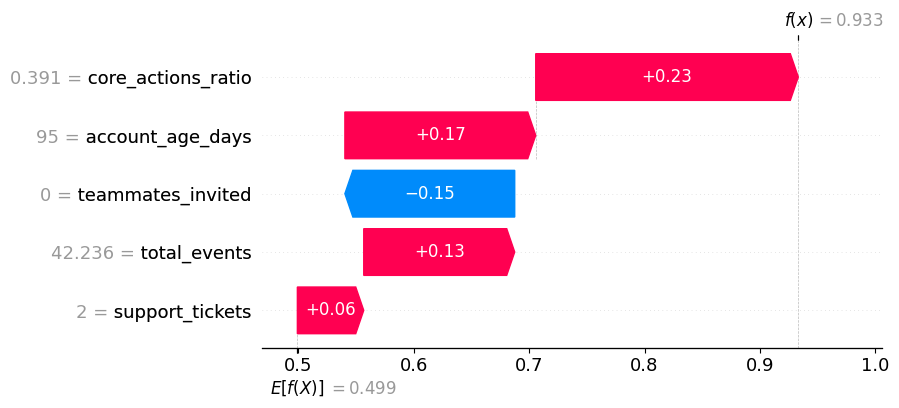

In [48]:
# Waterfall plot for first row of test set (Local Interpretability)
shap.plots.waterfall(entire_shap[323, :, 0])